# 02 — Huấn luyện mô hình: Linear Regression, Ridge, Lasso, Elastic Net và Random Forest

Notebook này huấn luyện các mô hình hồi quy trên tập huấn luyện (`train.parquet`), chọn siêu tham số **α** bằng kiểm định chéo, đánh giá **một lần** trên tập kiểm tra (`test.parquet`) và lưu mô hình + bảng kết quả + hình cho báo cáo và demo.

| Mục | Nội dung | Đầu ra chính |
|---|---|---|
| 1 | Cấu hình, nạp dữ liệu, tiền xử lý (Pipeline) | — |
| 2 | Chọn α bằng kiểm định chéo: `RidgeCV` (LOO), `LassoCV`, `ElasticNetCV` (5-fold), quy tắc 1-SE; Linear Regression; Random Forest | `models/*.joblib` |
| 3 | Kết quả trên tập kiểm tra | `ket_qua_so_sanh_mo_hinh.csv`, hình 06 |
| 4 | Đường lỗi CV theo α | hình 01 |
| 5 | Đường đi hệ số (coefficient path), lựa chọn đặc trưng của Lasso, cặp biến tương quan phòng ngủ – phòng vệ sinh | hình 02–04, `lasso_thu_tu_chon_dac_trung.csv`, `lasso_1se_dac_trung_bi_loai.csv`, `he_so_bien_so_theo_mo_hinh.csv` |
| 6 | Random Forest: độ quan trọng đặc trưng | hình 05, `rf_feature_importance.csv` |
| 7 | Phân tích lỗi: dự đoán so với thực tế, theo phân khúc giá, theo quận | hình 07–08, `mape_theo_phan_khuc.csv`, `mape_theo_quan.csv` |
| 8 | Thí nghiệm kích thước dữ liệu: khi nào chính quy hoá có ích? | hình 09, `thi_nghiem_kich_thuoc_du_lieu.csv` |
| 9 | Lưu mô hình và siêu dữ liệu cho demo | `models/demo_meta.json` |

**Nguyên tắc:** mọi lựa chọn (α, ρ, đặc trưng) dựa trên kiểm định chéo **trong tập train**; tập test chỉ dùng để đánh giá cuối (mục 3 trở đi). Mọi thứ ngẫu nhiên cố định bằng `SEED = 42`.

Notebook `04_danh_gia_bo_sung_va_cai_tien.ipynb` đọc các mô hình lưu ở đây (α, ρ) rồi bổ sung baseline, kiểm định chéo 5-fold, Gradient Boosting; vì vậy **chạy notebook này trước notebook 04**.

⏱ Thời gian chạy ước tính trên CPU 12 luồng: khoảng 8–10 phút (đo khi chạy lại; phần lâu nhất là `ElasticNetCV` và thí nghiệm kích thước dữ liệu).

## 1. Cấu hình, nạp dữ liệu và tiền xử lý

In [1]:
import os, json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, Lasso, ElasticNet, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Có thể đặt biến môi trường ML_PROJECT_DIR để chạy trên máy khác (không phụ thuộc đường dẫn cá nhân)
def find_project_dir():
    # Thứ tự ưu tiên: (1) biến môi trường ML_PROJECT_DIR; (2) Colab: thư mục dự án trên Google Drive;
    # (3) chạy trên máy: thư mục gốc dự án (nơi có requirements.txt) — thư mục hiện tại hoặc thư mục cha
    if os.environ.get("ML_PROJECT_DIR"):
        return os.environ["ML_PROJECT_DIR"]
    if IN_COLAB:
        return "/content/drive/MyDrive/ML_house_price"
    here = os.path.abspath(os.getcwd())
    for p in (here, os.path.dirname(here)):
        if os.path.isfile(os.path.join(p, "requirements.txt")):
            return p
    return here

PROJECT_DIR = find_project_dir()
DATA_DIR, MODEL_DIR = f"{PROJECT_DIR}/data_processed", f"{PROJECT_DIR}/models"
RES_DIR, FIG_DIR = f"{PROJECT_DIR}/results", f"{PROJECT_DIR}/figures/02"
for d in [MODEL_DIR, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
MIN_FREQ = 30            # danh mục (quận/phường/…) có < 30 tin trong tập huấn luyện được gộp vào nhóm "hiếm"
RF_SAMPLE = 50_000       # Random Forest học trên mẫu con 50.000 tin (phân tầng theo quận) để giới hạn thời gian
ALPHAS_LASSO = np.logspace(-6, 0, 50)     # lưới 50 giá trị α cho LassoCV / ElasticNetCV
ALPHAS_RIDGE = np.logspace(-3, 4, 50)     # lưới 50 giá trị α cho RidgeCV
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9]     # ρ (l1_ratio) cho ElasticNetCV
ALPHAS_PATH = np.logspace(-5.5, 0, 90)[::-1]   # lưới α (giảm dần) để vẽ đường đi hệ số của Lasso / Elastic Net
ALPHAS_PATH_RIDGE = np.logspace(-2, 6, 40)     # lưới α cho đường đi hệ số của Ridge
PATH_SAMPLE = 50_000                      # đường đi hệ số tính trên mẫu con 50.000 tin của tập train (cho nhanh)
print("sklearn", sklearn.__version__, "|", PROJECT_DIR)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)

def save_table(df, name, index=True):
    p = os.path.join(RES_DIR, f"{name}.csv"); df.to_csv(p, index=index, encoding="utf-8-sig"); print("Đã lưu:", p)

sklearn 1.6.1 | D:\HocMay_GiaNha_KT1


In [2]:
cfg = json.load(open(os.path.join(DATA_DIR, "feature_config.json"), encoding="utf-8"))
NUM, BIN = cfg["num_features"], cfg["bin_features"]
CAT = ["district_key", "ward_loc", "house_direction", "road_type"]     # ward_loc = quận | phường (phường chỉ có nghĩa trong quận)
FEATURES = NUM + BIN + CAT

def prepare(df):
    df = df.copy()
    for c in ["district_key", "ward_new", "house_direction", "road_type"]:
        df[c] = df[c].fillna("unknown").astype(str).replace("", "unknown")
    df["ward_loc"] = df["district_key"] + " | " + df["ward_new"]
    for c in BIN:
        df[c] = df[c].fillna(0).astype(int)
    return df

train = prepare(pd.read_parquet(os.path.join(DATA_DIR, "train.parquet")))
test  = prepare(pd.read_parquet(os.path.join(DATA_DIR, "test.parquet")))
X_train, y_train = train[FEATURES], train["price"].to_numpy()
X_test,  y_test  = test[FEATURES],  test["price"].to_numpy()
print(f"Train {X_train.shape} | Test {X_test.shape}")
print("Giá (tỷ): train median {:.2f}, test median {:.2f}".format(np.median(y_train) / 1e9, np.median(y_test) / 1e9))

Train (312092, 17) | Test (78077, 17)
Giá (tỷ): train median 12.40, test median 12.40


### Tiền xử lý trong Pipeline

Mọi phép biến đổi nằm **trong** `Pipeline` nên chỉ được học (fit) từ dữ liệu huấn luyện:

| Nhóm cột | Biến đổi | Lý do |
|---|---|---|
| 6 biến số | `SimpleImputer(median, add_indicator=True)` → `StandardScaler` | điền trung vị + cờ "thiếu"; chuẩn hoá để mức phạt α công bằng giữa các biến |
| 7 cờ nhị phân | giữ nguyên 0/1 | đã cùng thang |
| 4 biến phân loại | `OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist")` | gộp quận/phường hiếm (< 30 tin) để hệ số không nhiễu; danh mục mới ở tập test → nhóm hiếm |
| Linear Regression | thêm `drop="first"` | tránh bẫy biến giả (cộng tuyến hoàn hảo với hệ số chặn) |
| Nhãn | `TransformedTargetRegressor(log, exp)` | học log(giá), dự đoán trả về VND |

In [3]:
def build_preprocessor(drop=None, min_freq=MIN_FREQ):
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
        ("bin", "passthrough", BIN),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq,
                              drop=drop, sparse_output=False), CAT)], sparse_threshold=0)

def ttr(pipe):
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp, check_inverse=False)

def linear(reg, drop=None, min_freq=MIN_FREQ):
    return ttr(Pipeline([("pre", build_preprocessor(drop=drop, min_freq=min_freq)), ("reg", reg)]))

def feature_names(pre):
    # tên cột sau tiền xử lý, bỏ tiền tố nhóm của ColumnTransformer ("num__", "cat__", …)
    return np.array([n.split("__", 1)[1] for n in pre.get_feature_names_out()])

def group_of(name):
    if name in NUM: return "biến số"
    if name.startswith("missingindicator_"): return "cờ thiếu"
    if name in BIN: return "cờ văn bản"
    if name.startswith("district_key_"): return "quận"
    if name.startswith("ward_loc_"): return "phường"
    if name.startswith("house_direction_"): return "hướng nhà"
    if name.startswith("road_type_"): return "loại đường"
    return "khác"
GROUPS = ["biến số", "cờ thiếu", "cờ văn bản", "quận", "phường", "hướng nhà", "loại đường"]

def evaluate(model, X, y):
    # MAE/RMSE tính theo VND rồi đổi sang tỷ; MAPE, MdAPE theo %; RMSE và R² tính trên log(giá)
    p = model.predict(X); e = p - y
    return {"MAE (tỷ)": np.mean(np.abs(e)) / 1e9, "RMSE (tỷ)": np.sqrt(np.mean(e ** 2)) / 1e9,
            "MAPE (%)": np.mean(np.abs(e) / y) * 100, "MdAPE (%)": np.median(np.abs(e) / y) * 100,
            "RMSE log": np.sqrt(np.mean((np.log(y) - np.log(p)) ** 2)), "R² log": r2_score(np.log(y), np.log(p))}

## 2. Chọn α bằng kiểm định chéo và huấn luyện các mô hình

**Vì sao không chọn α trên chính dữ liệu huấn luyện?** Sai số huấn luyện luôn nhỏ nhất khi α → 0 (không phạt); α chỉ có ý nghĩa nếu đo bằng dữ liệu *chưa dùng để khớp* → kiểm định chéo.

| Mô hình | Cách chọn siêu tham số | Chi tiết |
|---|---|---|
| Linear Regression | — | bình phương tối thiểu thường (OLS), `drop="first"` |
| Ridge | `RidgeCV` | lưới 50 giá trị α trong [10⁻³, 10⁴]; *leave-one-out* theo công thức đóng (hiệu quả, không cần chia fold) |
| Lasso | `LassoCV` | lưới 50 giá trị α trong [10⁻⁶, 1]; **5-fold** |
| Elastic Net | `ElasticNetCV` | cùng lưới α; ρ ∈ {0,1; 0,3; 0,5; 0,7; 0,9}; **5-fold** |
| Lasso (1-SE) | quy tắc 1-SE trên đường lỗi của `LassoCV` | α lớn nhất mà lỗi CV còn nằm trong **một sai số chuẩn** của α tốt nhất → mô hình đơn giản hơn, độ chính xác gần như không đổi; sau đó huấn luyện lại trên toàn bộ tập train |
| Random Forest | cố định: 150 cây, `min_samples_leaf=3`, `max_features=0,33` | học trên **mẫu con 50.000 tin phân tầng theo quận** (mỗi quận lấy `round(n_quận × 50.000 / n_train)` tin; quận quá ít tin có thể không có mặt); tối ưu siêu tham số RF làm ở notebook 04 |

> Lưu ý: `scikit-learn` chia tổng bình phương sai số cho 2n ở Lasso/Elastic Net nhưng không chia ở Ridge, nên giá trị α của hai họ mô hình **không so sánh trực tiếp** với nhau. `LassoCV`/`ElasticNetCV` nhận `cv=5` (KFold không xáo trộn). Vì `train.parquet` được lưu theo ngày đăng giảm dần (tin mới → tin cũ), 5 fold này thực chất là 5 khối thời gian liên tiếp — một dạng kiểm định chéo theo khối thời gian. α* vẫn nằm ở cận dưới lưới nên kết luận không đổi; mọi so sánh giữa các mô hình ở notebook 04 dùng `KFold(shuffle=True, random_state=42)`.

In [4]:
FIT_SEC, MODELS = {}, {}

def fit_timed(name, model, X=X_train, y=y_train):
    t0 = time.time(); model.fit(X, y); FIT_SEC[name] = time.time() - t0
    MODELS[name] = model; print(f"{name:20s} huấn luyện xong sau {FIT_SEC[name]:7.1f}s")
    return model

fit_timed("Linear Regression", linear(LinearRegression(), drop="first"))
fit_timed("Ridge", linear(RidgeCV(alphas=ALPHAS_RIDGE, store_cv_results=True)))
fit_timed("Lasso", linear(LassoCV(alphas=ALPHAS_LASSO, cv=5, max_iter=20_000, n_jobs=-1, precompute=True, random_state=SEED)))
fit_timed("Elastic Net", linear(ElasticNetCV(alphas=ALPHAS_LASSO, l1_ratio=L1_RATIOS, cv=5, max_iter=20_000,
                                              n_jobs=-1, precompute=True, random_state=SEED)))

Linear Regression    huấn luyện xong sau     6.5s


Ridge                huấn luyện xong sau    38.5s


Lasso                huấn luyện xong sau    13.9s


Elastic Net          huấn luyện xong sau   212.7s


TransformedTargetRegressor(check_inverse=False, func=<ufunc 'log'>,
                           inverse_func=<ufunc 'exp'>,
                           regressor=Pipeline(steps=[('pre',
                                                      ColumnTransformer(sparse_threshold=0,
                                                                        transformers=[('num',
                                                                                       Pipeline(steps=[('simpleimputer',
                                                                                                        SimpleImputer(add_indicator=True,
                                                                                                                      strategy='median')),
                                                                                                       ('standardscaler',
                                                                                                        StandardScaler())]),
                                                                                       ['log_area',
                                                                                        'floor_count',
                                                                                        'bedroom_count',
                                                                                        'b...
       8.28642773e-03, 1.09854114e-02, 1.45634848e-02, 1.93069773e-02,
       2.55954792e-02, 3.39322177e-02, 4.49843267e-02, 5.96362332e-02,
       7.90604321e-02, 1.04811313e-01, 1.38949549e-01, 1.84206997e-01,
       2.44205309e-01, 3.23745754e-01, 4.29193426e-01, 5.68986603e-01,
       7.54312006e-01, 1.00000000e+00]),
                                                                   cv=5,
                                                                   l1_ratio=[0.1,
                                                                             0.3,
                                                                             0.5,
                                                                             0.7,
                                                                             0.9],
                                                                   max_iter=20000,
                                                                   n_jobs=-1,
                                                                   precompute=True,
                                                                   random_state=42))]))

In [5]:
# Quy tắc 1-SE: sai số chuẩn của MSE CV = std giữa các fold / sqrt(số fold)
def one_se_alpha(cv_model):
    mse = cv_model.mse_path_.mean(axis=1)
    se = cv_model.mse_path_.std(axis=1, ddof=1) / np.sqrt(cv_model.mse_path_.shape[1])
    best = mse.argmin()
    return float(cv_model.alphas_[mse <= mse[best] + se[best]].max())

lasso_cv = MODELS["Lasso"].regressor_.named_steps["reg"]
ALPHA_1SE = one_se_alpha(lasso_cv)
print(f"Lasso: α* (CV) = {lasso_cv.alpha_:.3e} | α (1-SE) = {ALPHA_1SE:.3e}  (gấp {ALPHA_1SE / lasso_cv.alpha_:.0f} lần)")
fit_timed("Lasso (1-SE)", linear(Lasso(alpha=ALPHA_1SE, precompute=True, max_iter=20_000)))

ridge_reg = MODELS["Ridge"].regressor_.named_steps["reg"]
en_reg = MODELS["Elastic Net"].regressor_.named_steps["reg"]
print(f"Ridge: α* = {ridge_reg.alpha_:.4g} | Elastic Net: α* = {en_reg.alpha_:.3e}, ρ* = {en_reg.l1_ratio_}")

# Đường lỗi LOO của Ridge (RMSE theo log giá) — lấy ra để vẽ ở mục 4 rồi bỏ khỏi mô hình lưu (nặng ~ n × 50 số)
RIDGE_RMSE = np.sqrt(ridge_reg.cv_results_.mean(axis=0))
del ridge_reg.cv_results_

Lasso: α* (CV) = 3.089e-06 | α (1-SE) = 1.600e-04  (gấp 52 lần)


Lasso (1-SE)         huấn luyện xong sau     2.6s
Ridge: α* = 1.389 | Elastic Net: α* = 4.095e-06, ρ* = 0.9


In [6]:
# Random Forest trên mẫu con phân tầng theo quận: mỗi quận lấy round(n_quận × 50.000 / n_train) tin
def stratified_subsample(df, n, seed):
    frac = n / len(df)
    return df.groupby("district_key", group_keys=False).apply(
        lambda d: d.sample(n=int(round(len(d) * frac)), random_state=seed))

rf_sub = stratified_subsample(train, RF_SAMPLE, SEED)
print(f"Mẫu con Random Forest: {len(rf_sub):,} tin ({rf_sub['district_key'].nunique()} quận)")
rf = ttr(Pipeline([("pre", build_preprocessor()),
                   ("reg", RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.33,
                                                 n_jobs=-1, random_state=SEED))]))
fit_timed("Random Forest", rf, rf_sub[FEATURES], rf_sub["price"].to_numpy())

Mẫu con Random Forest: 50,001 tin (29 quận)


Random Forest        huấn luyện xong sau     7.2s


TransformedTargetRegressor(check_inverse=False, func=<ufunc 'log'>,
                           inverse_func=<ufunc 'exp'>,
                           regressor=Pipeline(steps=[('pre',
                                                      ColumnTransformer(sparse_threshold=0,
                                                                        transformers=[('num',
                                                                                       Pipeline(steps=[('simpleimputer',
                                                                                                        SimpleImputer(add_indicator=True,
                                                                                                                      strategy='median')),
                                                                                                       ('standardscaler',
                                                                                                        StandardScaler())]),
                                                                                       ['log_area',
                                                                                        'floor_count',
                                                                                        'bedroom_count',
                                                                                        'b...
                                                                                       ['has_so_do',
                                                                                        'car_access',
                                                                                        'is_mat_pho',
                                                                                        'kinh_doanh',
                                                                                        'lo_goc',
                                                                                        'no_hau',
                                                                                        'thang_may']),
                                                                                      ('cat',
                                                                                       OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                                     min_frequency=30,
                                                                                                     sparse_output=False),
                                                                                       ['district_key',
                                                                                        'ward_loc',
                                                                                        'house_direction',
                                                                                        'road_type'])])),
                                                     ('reg',
                                                      RandomForestRegressor(max_features=0.33,
                                                                            min_samples_leaf=3,
                                                                            n_estimators=150,
                                                                            n_jobs=-1,
                                                                            random_state=42))]))

## 3. Kết quả trên tập kiểm tra

Đánh giá **một lần** trên tập test. Các cột: MAE, RMSE (tỷ VND), MAPE và MdAPE (%), RMSE và R² trên log(giá), MAPE trên tập huấn luyện (để nhận diện quá khớp; với Random Forest là MAPE trên chính 50.000 tin đã học), α, ρ và số hệ số khác 0 của mô hình tuyến tính.

In [7]:
ORDER = ["Linear Regression", "Ridge", "Lasso", "Elastic Net", "Lasso (1-SE)", "Random Forest"]
rows = []
for n in ORDER:
    m = MODELS[n]; reg = m.regressor_.named_steps["reg"]
    row = {"mô hình": n, **evaluate(m, X_test, y_test)}
    Xtr_eval, ytr_eval = (rf_sub[FEATURES], rf_sub["price"].to_numpy()) if n == "Random Forest" else (X_train, y_train)
    row["MAPE train (%)"] = evaluate(m, Xtr_eval, ytr_eval)["MAPE (%)"]
    row["alpha"] = float(getattr(reg, "alpha_", getattr(reg, "alpha", np.nan))) if n != "Random Forest" else np.nan
    row["l1_ratio"] = float(getattr(reg, "l1_ratio_", np.nan))
    row["số hệ số ≠ 0"] = float((reg.coef_ != 0).sum()) if hasattr(reg, "coef_") else np.nan
    row["thời gian (s)"] = FIT_SEC[n]
    rows.append(row)
results = pd.DataFrame(rows).set_index("mô hình")
display(results.round(4))
save_table(results.round(6).reset_index(), "ket_qua_so_sanh_mo_hinh", index=False)

,MAE (tỷ),RMSE (tỷ),MAPE (%),MdAPE (%),RMSE log,R² log,MAPE train (%),alpha,l1_ratio,số hệ số ≠ 0,thời gian (s)
mô hình,,,,,,,,,,,
Linear Regression,4.4558,10.3836,22.4426,17.1933,0.2821,0.8420,22.3966,NaN,NaN,307.0,6.4703
Ridge,4.4557,10.3826,22.4424,17.1915,0.2821,0.8420,22.3965,1.3895,NaN,311.0,38.5026
Lasso,4.4555,10.3802,22.4415,17.1970,0.2821,0.8420,22.3960,0.0000,NaN,290.0,13.9001
Elastic Net,4.4555,10.3797,22.4418,17.1942,0.2821,0.8420,22.3962,0.0000,0.9,287.0,212.6790
Lasso (1-SE),4.5039,10.4892,22.7334,17.4063,0.2856,0.8382,22.7321,0.0002,NaN,165.0,2.5926
Random Forest,4.3361,10.4547,21.7450,15.7215,0.2821,0.8420,15.3460,NaN,NaN,NaN,7.2314


Đã lưu: D:\HocMay_GiaNha_KT1/results\ket_qua_so_sanh_mo_hinh.csv


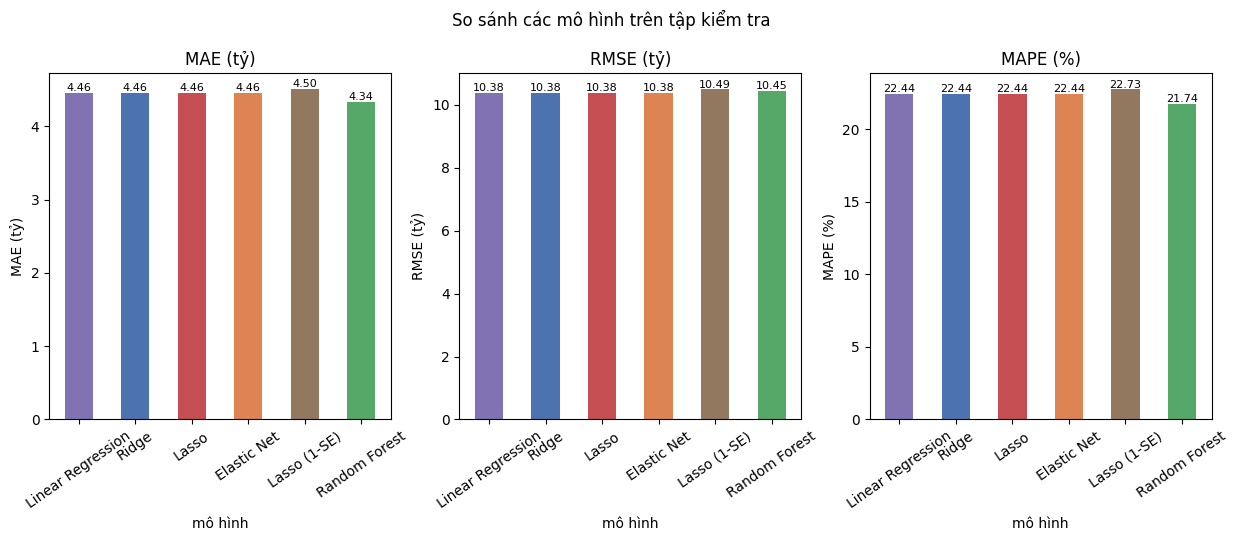

In [8]:
colors = {"Linear Regression": "#8172B3", "Ridge": "#4C72B0", "Lasso": "#C44E52", "Elastic Net": "#DD8452",
          "Lasso (1-SE)": "#937860", "Random Forest": "#55A868"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["MAE (tỷ)", "RMSE (tỷ)", "MAPE (%)"]):
    ax.bar(results.index, results[col], color=[colors[i] for i in results.index], width=0.5)
    for i, v in enumerate(results[col]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(col); ax.set_xlabel("mô hình"); ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("So sánh các mô hình trên tập kiểm tra", y=1.02)
save_fig(fig, "06_so_sanh_mo_hinh")

**Cách đọc:** nếu các mô hình tuyến tính (Linear, Ridge, Lasso, Elastic Net) cho kết quả gần như trùng nhau thì lý do là với ~300 nghìn mẫu so với ~300 cột, phương sai ước lượng hệ số đã rất thấp nên chính quy hoá gần như không cần thiết để giảm sai số (mục 8 kiểm chứng điều này). Lasso 1-SE đánh đổi một chút sai số để dùng ít đặc trưng hơn. Với Random Forest, so sánh MAPE train (trên mẫu con đã học) và MAPE test cho thấy mức quá khớp thật của nó.

## 4. Đường lỗi kiểm định chéo theo α

Vẽ RMSE (trên log giá) theo α cho `RidgeCV` (LOO), `LassoCV` (trung bình ± độ lệch chuẩn giữa 5 fold) và `ElasticNetCV` (một đường cho mỗi ρ). Đường đứng nét đứt là α\* (lỗi CV nhỏ nhất); đường chấm xanh là α theo quy tắc 1-SE.

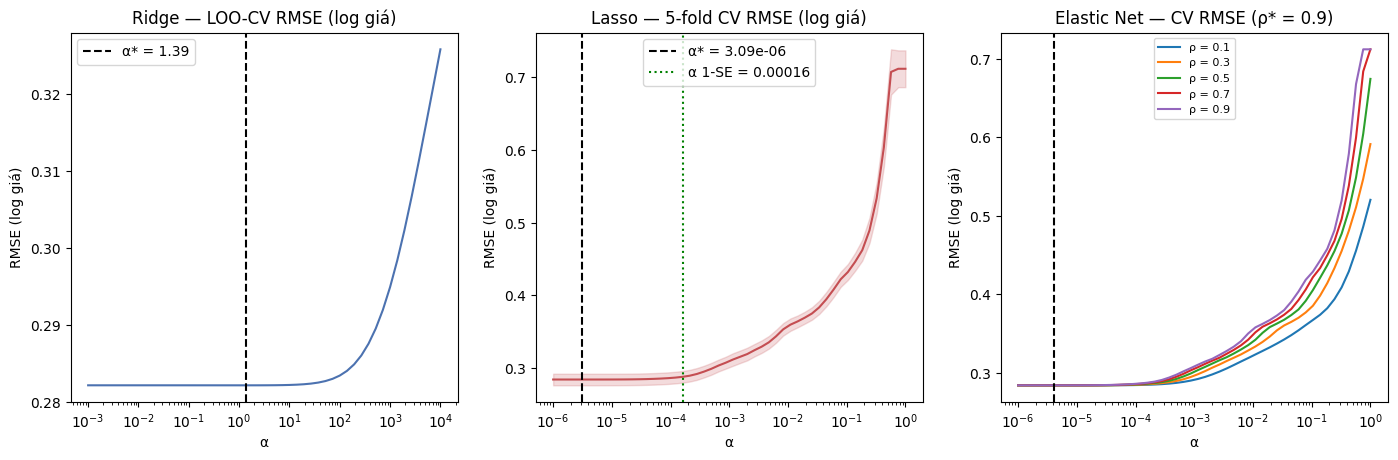

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.semilogx(ALPHAS_RIDGE, RIDGE_RMSE, color="#4C72B0")
ax.axvline(ridge_reg.alpha_, color="k", ls="--", label=f"α* = {ridge_reg.alpha_:.3g}")
ax.set(xlabel="α", ylabel="RMSE (log giá)", title="Ridge — LOO-CV RMSE (log giá)"); ax.legend()

ax = axes[1]
a = lasso_cv.alphas_; rm = np.sqrt(lasso_cv.mse_path_)           # (n_alpha, n_fold)
mean, sd = rm.mean(axis=1), rm.std(axis=1)
ax.semilogx(a, mean, color="#C44E52"); ax.fill_between(a, mean - sd, mean + sd, color="#C44E52", alpha=0.2)
ax.axvline(lasso_cv.alpha_, color="k", ls="--", label=f"α* = {lasso_cv.alpha_:.3g}")
ax.axvline(ALPHA_1SE, color="g", ls=":", label=f"α 1-SE = {ALPHA_1SE:.3g}")
ax.set(xlabel="α", ylabel="RMSE (log giá)", title="Lasso — 5-fold CV RMSE (log giá)"); ax.legend()

ax = axes[2]
a_en = np.atleast_2d(en_reg.alphas_)
for k, r in enumerate(L1_RATIOS):
    aa = a_en[k] if a_en.shape[0] > 1 else a_en[0]
    ax.semilogx(aa, np.sqrt(en_reg.mse_path_[k]).mean(axis=1), label=f"ρ = {r}")
ax.axvline(en_reg.alpha_, color="k", ls="--")
ax.set(xlabel="α", ylabel="RMSE (log giá)", title=f"Elastic Net — CV RMSE (ρ* = {en_reg.l1_ratio_})"); ax.legend(fontsize=8)
save_fig(fig, "01_loi_cv_theo_alpha")

## 5. Đường đi hệ số, lựa chọn đặc trưng của Lasso

**Coefficient path:** huấn luyện lại Lasso, Elastic Net (ρ = 0,5) và Ridge trên lưới α, α giảm dần (khởi động nóng `warm_start`), và ghi lại toàn bộ hệ số. Để chạy nhanh, đường đi được tính trên **mẫu con 50.000 tin của tập train** (`numpy.random.default_rng(42).choice`), trên dữ liệu đã qua bộ tiền xử lý của mô hình Lasso. Vì thế các hệ số trên đường đi **không hoàn toàn bằng** hệ số của mô hình cuối (huấn luyện trên toàn bộ train); cột "hệ số tại α\*" của bảng bên dưới lấy từ mô hình cuối.

In [10]:
pre_lasso = MODELS["Lasso"].regressor_.named_steps["pre"]
NAMES = feature_names(pre_lasso)                       # các cột sau tiền xử lý
GROUP = np.array([group_of(n) for n in NAMES])
Z_all = pre_lasso.transform(X_train); ylog_all = np.log(y_train)
path_idx = np.random.default_rng(SEED).choice(len(Z_all), PATH_SAMPLE, replace=False)
Zp, yp = Z_all[path_idx], ylog_all[path_idx]

def coef_path(make_model, alphas):
    # trả về ma trận hệ số (số đặc trưng × số α), cột ứng với từng α theo thứ tự trong `alphas`
    m, out = make_model(), []
    for a in alphas:
        m.set_params(alpha=a); m.fit(Zp, yp); out.append(m.coef_.copy())
    return np.array(out).T

t0 = time.time()
PATH_LASSO = coef_path(lambda: Lasso(warm_start=True, precompute=True, max_iter=20_000), ALPHAS_PATH)
PATH_EN = coef_path(lambda: ElasticNet(l1_ratio=0.5, warm_start=True, precompute=True, max_iter=20_000), ALPHAS_PATH)
PATH_RIDGE = coef_path(lambda: Ridge(solver="cholesky"), ALPHAS_PATH_RIDGE)
print(f"Tính đường đi hệ số: {time.time() - t0:.0f}s | số đặc trưng: {len(NAMES)}")

Tính đường đi hệ số: 36s | số đặc trưng: 311


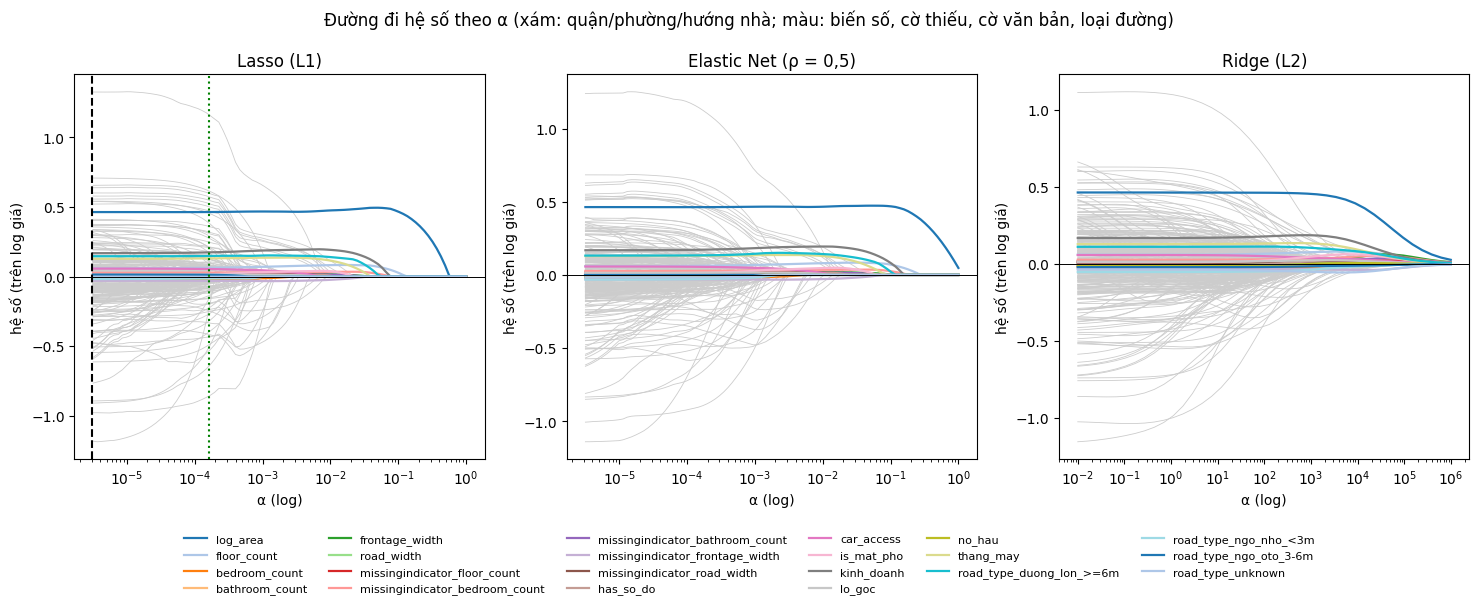

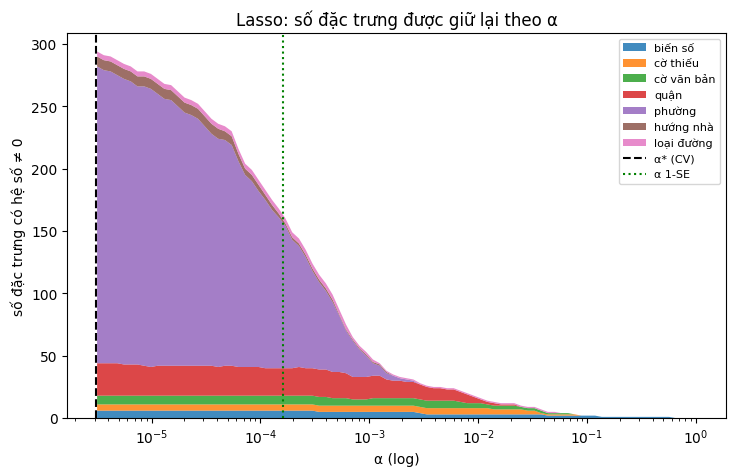

In [11]:
# --- Hình 02: đường đi hệ số ---
core = [i for i, g in enumerate(GROUP) if g not in ("quận", "phường", "hướng nhà")]
geo = [i for i, g in enumerate(GROUP) if g in ("quận", "phường", "hướng nhà")]
cmap = plt.get_cmap("tab20")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, al, path) in zip(axes, [("Lasso (L1)", ALPHAS_PATH, PATH_LASSO), ("Elastic Net (ρ = 0,5)", ALPHAS_PATH, PATH_EN),
                                        ("Ridge (L2)", ALPHAS_PATH_RIDGE, PATH_RIDGE)]):
    for i in geo:
        ax.semilogx(al, path[i], color="#cccccc", lw=0.6)
    for k, i in enumerate(core):
        ax.semilogx(al, path[i], color=cmap(k % 20), lw=1.6, label=NAMES[i] if title.startswith("Lasso") else None)
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xlabel="α (log)", ylabel="hệ số (trên log giá)", title=title)
axes[0].axvline(lasso_cv.alpha_, color="k", ls="--"); axes[0].axvline(ALPHA_1SE, color="g", ls=":")
# chú giải đặt dưới hình để không che đường đi hệ số của Lasso
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=6, fontsize=8, frameon=False)
fig.suptitle("Đường đi hệ số theo α (xám: quận/phường/hướng nhà; màu: biến số, cờ thiếu, cờ văn bản, loại đường)", y=1.01)
save_fig(fig, "02_coefficient_path")

# --- Hình 03: số đặc trưng Lasso giữ lại theo α, tách theo nhóm ---
cnt = np.array([[((PATH_LASSO[:, j] != 0) & (GROUP == g)).sum() for j in range(len(ALPHAS_PATH))] for g in GROUPS])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.stackplot(ALPHAS_PATH, cnt, labels=GROUPS, alpha=0.85)
ax.set_xscale("log")
ax.axvline(lasso_cv.alpha_, color="k", ls="--", label="α* (CV)"); ax.axvline(ALPHA_1SE, color="g", ls=":", label="α 1-SE")
ax.set(xlabel="α (log)", ylabel="số đặc trưng có hệ số ≠ 0", title="Lasso: số đặc trưng được giữ lại theo α")
ax.legend(fontsize=8, loc="upper right")
save_fig(fig, "03_so_dac_trung_theo_alpha")

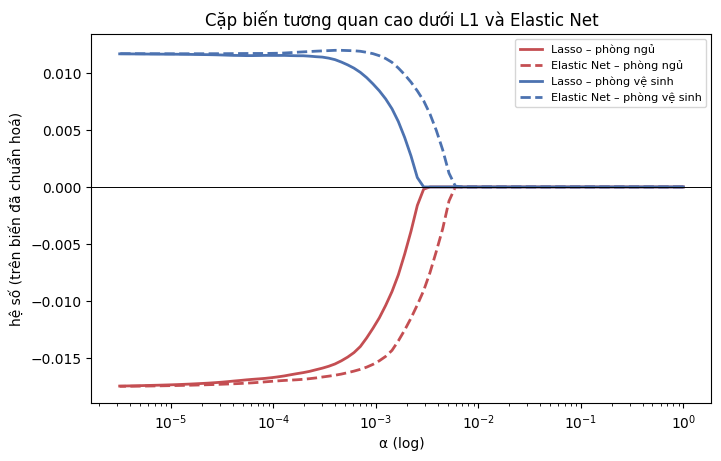

Hệ số tương quan phòng ngủ – phòng vệ sinh trong tập train: 0.953


In [12]:
# --- Hình 04: cặp biến tương quan cao (phòng ngủ – phòng vệ sinh) dưới L1 và Elastic Net ---
ib, iw = NAMES.tolist().index("bedroom_count"), NAMES.tolist().index("bathroom_count")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.semilogx(ALPHAS_PATH, PATH_LASSO[ib], color="#C44E52", lw=2, label="Lasso – phòng ngủ")
ax.semilogx(ALPHAS_PATH, PATH_EN[ib], color="#C44E52", lw=2, ls="--", label="Elastic Net – phòng ngủ")
ax.semilogx(ALPHAS_PATH, PATH_LASSO[iw], color="#4C72B0", lw=2, label="Lasso – phòng vệ sinh")
ax.semilogx(ALPHAS_PATH, PATH_EN[iw], color="#4C72B0", lw=2, ls="--", label="Elastic Net – phòng vệ sinh")
ax.axhline(0, color="k", lw=0.7)
ax.set(xlabel="α (log)", ylabel="hệ số (trên biến đã chuẩn hoá)", title="Cặp biến tương quan cao dưới L1 và Elastic Net")
ax.legend(fontsize=8)
save_fig(fig, "04_cap_phong_ngu_wc")
corr = train[["bedroom_count", "bathroom_count"]].corr().iloc[0, 1]
print(f"Hệ số tương quan phòng ngủ – phòng vệ sinh trong tập train: {corr:.3f}")

### Thứ tự đặc trưng được Lasso chọn

Với mỗi đặc trưng, **α khi bắt đầu được chọn** là α lớn nhất trên lưới (đường đi ở trên) mà hệ số của nó khác 0 — đặc trưng được chọn sớm (α lớn) là đặc trưng quan trọng nhất. Đặc trưng không bao giờ khác 0 trên lưới có giá trị 0 (xếp cuối). Sắp xếp bằng `Series.sort_values(ascending=False)`; các đặc trưng đồng giá trị (cùng vào ở một α) có thứ tự trong nhóm phụ thuộc vào thuật toán sắp xếp mặc định của pandas, **không** mang ý nghĩa. Cột "hệ số tại α\*" lấy từ mô hình Lasso cuối (huấn luyện trên toàn bộ train).

In [13]:
nz = PATH_LASSO != 0
ever = nz.any(axis=1)
first = np.where(ever, nz.argmax(axis=1), 0)
enter = pd.Series(np.where(ever, ALPHAS_PATH[first], 0.0), index=NAMES)
order = enter.sort_values(ascending=False).index
coef_final = pd.Series(MODELS["Lasso"].regressor_.named_steps["reg"].coef_, index=NAMES)
rank_tab = pd.DataFrame({"đặc trưng": order, "nhóm": [group_of(n) for n in order],
                         "α khi bắt đầu được chọn": enter[order].to_numpy(), "hệ số tại α*": coef_final[order].to_numpy()},
                        index=np.arange(1, len(order) + 1))
display(rank_tab.head(12))
save_table(rank_tab, "lasso_thu_tu_chon_dac_trung")

# Đặc trưng bị Lasso 1-SE loại (hệ số = 0), theo nhóm
reg_1se = MODELS["Lasso (1-SE)"].regressor_.named_steps["reg"]
names_1se = feature_names(MODELS["Lasso (1-SE)"].regressor_.named_steps["pre"])
dropped = pd.DataFrame({"đặc trưng": names_1se, "nhóm": [group_of(n) for n in names_1se], "hệ số": reg_1se.coef_})
dropped = dropped[dropped["hệ số"] == 0].reset_index(drop=True)
print(f"Lasso 1-SE giữ {(reg_1se.coef_ != 0).sum()}/{len(names_1se)} đặc trưng, loại {len(dropped)}:")
print(dropped["nhóm"].value_counts().to_string())
save_table(dropped, "lasso_1se_dac_trung_bi_loai", index=False)

,đặc trưng,nhóm,α khi bắt đầu được chọn,hệ số tại α*
1,log_area,biến số,0.565990,0.464144
2,floor_count,biến số,0.118313,0.059480
3,missingindicator_bedroom_count,cờ thiếu,0.077204,0.025394
4,kinh_doanh,cờ văn bản,0.066964,0.167689
5,road_type_duong_lon_>=6m,loại đường,0.050379,0.150831
6,thang_may,cờ văn bản,0.037901,0.129178
7,frontage_width,biến số,0.037901,0.016531
8,missingindicator_frontage_width,cờ thiếu,0.032874,-0.028655
9,missingindicator_bathroom_count,cờ thiếu,0.032874,0.010986
10,missingindicator_floor_count,cờ thiếu,0.024732,0.012343


Đã lưu: D:\HocMay_GiaNha_KT1/results\lasso_thu_tu_chon_dac_trung.csv
Lasso 1-SE giữ 165/311 đặc trưng, loại 146:
nhóm
phường       139
quận           4
hướng nhà      3
Đã lưu: D:\HocMay_GiaNha_KT1/results\lasso_1se_dac_trung_bi_loai.csv


In [14]:
# Hệ số (trên biến đã chuẩn hoá) của một số biến số theo từng mô hình tuyến tính
def coef_series(model):
    return pd.Series(model.regressor_.named_steps["reg"].coef_, index=feature_names(model.regressor_.named_steps["pre"]))
KEY = ["bedroom_count", "bathroom_count", "log_area", "floor_count", "frontage_width"]
coef_tab = pd.DataFrame({n: coef_series(MODELS[n])[KEY] for n in ["Linear Regression", "Ridge", "Lasso", "Elastic Net", "Lasso (1-SE)"]}).T
display(coef_tab.round(4))
save_table(coef_tab, "he_so_bien_so_theo_mo_hinh")

,bedroom_count,bathroom_count,log_area,floor_count,frontage_width
Linear Regression,-0.0168,0.0092,0.4641,0.0594,0.0165
Ridge,-0.0168,0.0092,0.4641,0.0594,0.0165
Lasso,-0.0168,0.0092,0.4641,0.0595,0.0165
Elastic Net,-0.0168,0.0092,0.4641,0.0595,0.0165
Lasso (1-SE),-0.0162,0.0092,0.4653,0.0622,0.0164


Đã lưu: D:\HocMay_GiaNha_KT1/results\he_so_bien_so_theo_mo_hinh.csv


**Gợi ý nhận xét cho báo cáo (đối chiếu với số liệu vừa chạy):** (i) α\* của Lasso/Elastic Net nằm ở đâu trên lưới (cận dưới hay giữa lưới) cho biết chính quy hoá có cần thiết hay không; (ii) vùng lỗi CV phẳng ở α nhỏ là lý do quy tắc 1-SE chọn được α lớn hơn nhiều mà sai số gần như không đổi; (iii) khi α tăng, hệ số của quận/phường thường về 0 trước, biến số và cờ văn bản được giữ lâu — xem hình 03 và bảng "bị loại" theo nhóm; (iv) phòng ngủ và phòng vệ sinh tương quan rất cao nên mô hình không tách được tác động riêng, dấu hệ số của hai biến này có thể trái trực giác (hình 04): L1 có xu hướng giữ một biến trong cặp và đưa biến kia về 0, còn Elastic Net (thành phần L2) giữ cả hai lâu hơn.

## 6. Random Forest: độ quan trọng đặc trưng

Độ quan trọng theo *impurity* (mức giảm tổng phương sai khi tách theo đặc trưng, trung bình trên các cây). Lưu ý: với biến phân loại đã one-hot, độ quan trọng bị chia nhỏ cho từng cột; thang đo này thiên về biến có nhiều giá trị khác nhau. Dùng để tham khảo, không thay cho kiểm định bằng ablation (notebook 04).

,importance
log_area,0.527976
frontage_width,0.081949
kinh_doanh,0.061827
thang_may,0.043760
road_type_duong_lon_>=6m,0.038003
bedroom_count,0.030072
floor_count,0.017206
missingindicator_bedroom_count,0.016446
is_mat_pho,0.015700
ward_loc_infrequent_sklearn,0.014780


Đã lưu: D:\HocMay_GiaNha_KT1/results\rf_feature_importance.csv


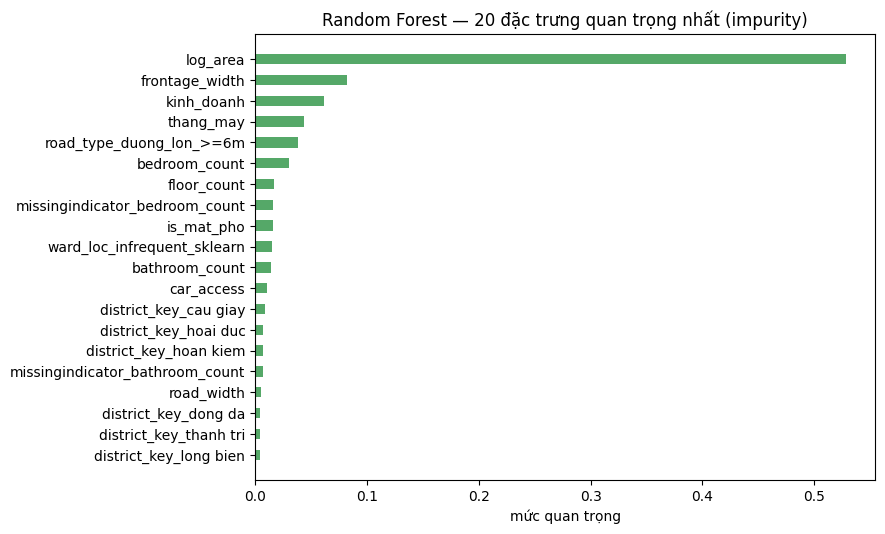

In [15]:
rf_pipe = MODELS["Random Forest"].regressor_
imp = pd.Series(rf_pipe.named_steps["reg"].feature_importances_, index=feature_names(rf_pipe.named_steps["pre"])).sort_values(ascending=False)
imp_tab = imp.to_frame("importance")
display(imp_tab.head(12))
save_table(imp_tab, "rf_feature_importance")
top = imp.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.8))
ax.barh(top.index, top.values, color="#55A868", height=0.5)
ax.set(xlabel="mức quan trọng", title="Random Forest — 20 đặc trưng quan trọng nhất (impurity)")
save_fig(fig, "05_rf_feature_importance")

## 7. Phân tích lỗi (Elastic Net và Random Forest)

- **Giá dự đoán so với giá thực** (thang log–log, 20.000 tin ngẫu nhiên của tập test).
- **MAPE theo phân khúc giá thực:** 10 nhóm thập phân vị của giá thực trên tập test.
- **MAPE theo quận/huyện:** MAPE trung bình của từng quận trên tập test, sắp theo số tin giảm dần.

Các bảng này cho thấy sai số có đồng đều hay không giữa các phân khúc giá và các quận — thông tin dùng để chỉ ra hạn chế của mô hình (xem notebook 04, mục 6).

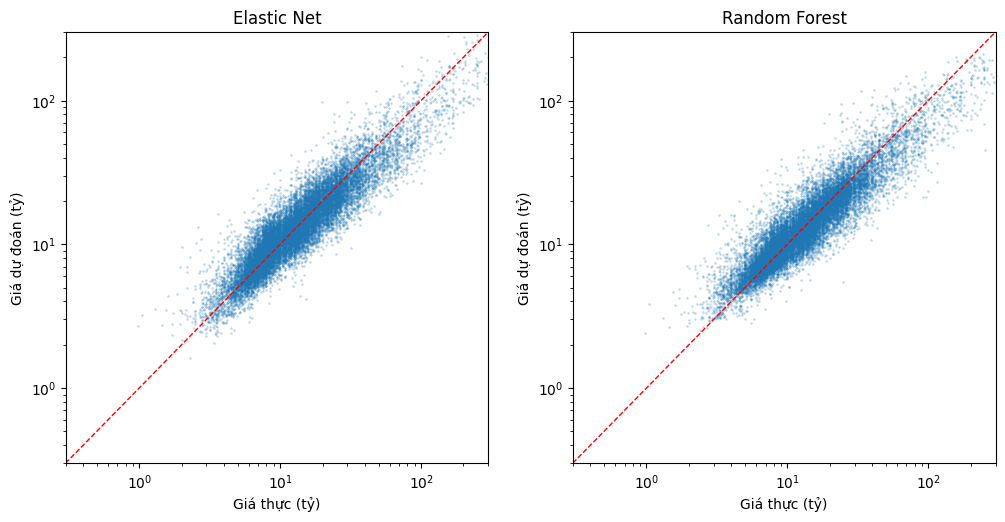

,Elastic Net,Random Forest
1.0–6.0 tỷ,26.98,32.02
6.0–7.4 tỷ,20.47,18.46
7.4–8.5 tỷ,22.65,18.57
8.5–10.0 tỷ,21.83,20.32
10.0–12.4 tỷ,20.60,19.73
12.4–14.7 tỷ,19.73,19.04
14.7–17.8 tỷ,21.05,19.39
17.8–22.9 tỷ,20.84,19.94
22.9–32.5 tỷ,21.67,21.64
32.5–300.0 tỷ,28.39,28.15


Đã lưu: D:\HocMay_GiaNha_KT1/results\mape_theo_phan_khuc.csv


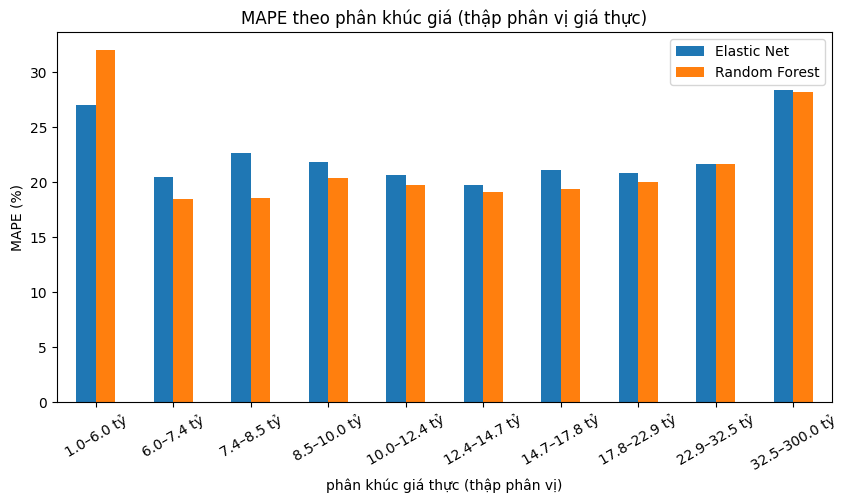

,Elastic Net,Random Forest,số tin test
dong da,24.45,20.70,9768
cau giay,22.67,20.13,9701
long bien,21.03,20.68,7892
thanh xuan,22.08,20.04,6480
ha dong,19.32,19.95,6473
hoang mai,20.73,20.25,6124
hai ba trung,24.51,22.16,6110
ba dinh,25.85,22.30,5853
nam tu liem,18.29,18.44,4971
tay ho,26.36,23.84,4759


Đã lưu: D:\HocMay_GiaNha_KT1/results\mape_theo_quan.csv


In [16]:
pred = {"Elastic Net": MODELS["Elastic Net"].predict(X_test), "Random Forest": MODELS["Random Forest"].predict(X_test)}
ape = {k: np.abs(v - y_test) / y_test for k, v in pred.items()}

# --- Hình 07: dự đoán vs thực tế ---
samp = np.random.default_rng(SEED).choice(len(y_test), min(20_000, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, (name, p) in zip(axes, pred.items()):
    ax.scatter(y_test[samp] / 1e9, p[samp] / 1e9, s=3, alpha=0.3, color="#1f77b4", linewidths=0)
    ax.plot([0.3, 300], [0.3, 300], "r--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.3, 300); ax.set_ylim(0.3, 300)
    ax.set(xlabel="Giá thực (tỷ)", ylabel="Giá dự đoán (tỷ)", title=name)
save_fig(fig, "07_du_doan_vs_thuc_te")

# --- MAPE theo phân khúc giá thực (10 nhóm thập phân vị) ---
dec = pd.qcut(y_test, 10)
seg = pd.DataFrame({k: v for k, v in ape.items()}).groupby(dec, observed=True).mean() * 100
seg.index = [f"{iv.left / 1e9:.1f}–{iv.right / 1e9:.1f} tỷ" for iv in seg.index]
display(seg.round(2))
save_table(seg.round(2), "mape_theo_phan_khuc")
fig, ax = plt.subplots(figsize=(10, 4.8))
seg.plot.bar(ax=ax, color=["#1f77b4", "#ff7f0e"], width=0.5)
ax.set(xlabel="phân khúc giá thực (thập phân vị)", ylabel="MAPE (%)", title="MAPE theo phân khúc giá (thập phân vị giá thực)")
ax.tick_params(axis="x", rotation=30)
save_fig(fig, "08_mape_theo_phan_khuc")

# --- MAPE theo quận ---
by_d = pd.DataFrame({k: v for k, v in ape.items()}).groupby(test["district_key"].to_numpy()).mean() * 100
by_d["số tin test"] = test["district_key"].value_counts().reindex(by_d.index)
by_d = by_d.sort_values("số tin test", ascending=False)
display(by_d.round(2).head(12))
save_table(by_d.round(2), "mape_theo_quan")

## 8. Thí nghiệm kích thước dữ liệu: khi nào chính quy hoá có ích?

Huấn luyện lại 4 mô hình tuyến tính trên các tập con của tập train với **n = 300, 1.000, 3.000, 10.000, 30.000, 100.000 và toàn bộ**, đánh giá trên **cùng tập test**. α được chọn lại bằng kiểm định chéo (cùng lưới và cùng cách như mục 2; Elastic Net cố định ρ = 0,5). Để số đặc trưng p lớn so với n, thí nghiệm dùng **`min_frequency = 5`** (giữ nhiều cột phường hơn mục 2).

- Mẫu con: `numpy.random.default_rng(100 + r).choice(n_train, n, replace=False)`, với r là chỉ số lần lặp.
- **Số lần lặp:** n ≤ 3.000 lặp **3 lần** (r = 0, 1, 2) rồi lấy trung bình — mẫu nhỏ nhiễu mạnh; số cột p cũng thay đổi giữa các lần (danh mục hiếm khác nhau) nên p, số hệ số ≠ 0 và α trung bình có thể là số lẻ; n ≥ 10.000 chạy **1 lần** (r = 0).
- Cột `p` = số cột đặc trưng sau tiền xử lý; Linear Regression có ít hơn 4 cột (do `drop="first"`).

In [17]:
SIZE_MIN_FREQ, SIZE_SEED_BASE = 5, 100
SIZES = [300, 1_000, 3_000, 10_000, 30_000, 100_000, len(X_train)]
def size_models():
    return {"Linear Regression": lambda: LinearRegression(),
            "Ridge": lambda: RidgeCV(alphas=ALPHAS_RIDGE),
            "Lasso": lambda: LassoCV(alphas=ALPHAS_LASSO, cv=5, max_iter=20_000, n_jobs=-1, precompute=True, random_state=SEED),
            "Elastic Net": lambda: ElasticNetCV(alphas=ALPHAS_LASSO, l1_ratio=0.5, cv=5, max_iter=20_000,
                                                n_jobs=-1, precompute=True, random_state=SEED)}
size_rows, t0 = [], time.time()
for n in SIZES:
    for r in range(3 if n <= 3_000 else 1):
        idx = np.random.default_rng(SIZE_SEED_BASE + r).choice(len(X_train), n, replace=False)
        Xs, ys = X_train.iloc[idx], y_train[idx]
        for name, mk in size_models().items():
            m = linear(mk(), drop="first" if name == "Linear Regression" else None, min_freq=SIZE_MIN_FREQ).fit(Xs, ys)
            reg = m.regressor_.named_steps["reg"]
            p_te, p_tr = m.predict(X_test), m.predict(Xs)
            size_rows.append({"n": n, "mô hình": name,
                              "RMSE log": np.sqrt(np.mean((np.log(y_test) - np.log(p_te)) ** 2)),
                              "MAPE (%)": np.mean(np.abs(p_te - y_test) / y_test) * 100,
                              "MAPE train (%)": np.mean(np.abs(p_tr - ys) / ys) * 100,
                              "alpha": getattr(reg, "alpha_", np.nan), "l1_ratio": getattr(reg, "l1_ratio_", np.nan),
                              "số hệ số ≠ 0": int((reg.coef_ != 0).sum()), "p": len(reg.coef_)})
        print(f"n = {n:>7,} | lần {r} xong | tổng {time.time() - t0:.0f}s", flush=True)
size_raw = pd.DataFrame(size_rows).groupby(["n", "mô hình"]).mean().reset_index()   # chưa làm tròn: dùng để vẽ hình
size_tab = size_raw.round(5)
display(size_tab[size_tab["mô hình"].isin(["Linear Regression", "Lasso"])])
save_table(size_tab, "thi_nghiem_kich_thuoc_du_lieu", index=False)

n =     300 | lần 0 xong | tổng 1s


n =     300 | lần 1 xong | tổng 1s


n =     300 | lần 2 xong | tổng 2s


n =   1,000 | lần 0 xong | tổng 2s


n =   1,000 | lần 1 xong | tổng 3s


n =   1,000 | lần 2 xong | tổng 4s


... (5 outputs left out)

n = 100,000 | lần 0 xong | tổng 50s


n = 312,092 | lần 0 xong | tổng 150s


,n,mô hình,RMSE log,MAPE (%),MAPE train (%),alpha,l1_ratio,số hệ số ≠ 0,p
1,300,Lasso,0.34308,27.33268,24.07147,0.00349,NaN,33.00000,56.33333
2,300,Linear Regression,0.34828,27.89485,23.04954,NaN,NaN,52.33333,52.33333
5,1000,Lasso,0.30591,24.34149,22.84538,0.00080,NaN,68.66667,123.66667
6,1000,Linear Regression,0.31099,24.95851,22.00408,NaN,NaN,119.66667,119.66667
9,3000,Lasso,0.29623,23.58097,22.76792,0.00014,NaN,156.66667,192.33333
10,3000,Linear Regression,0.29737,23.78886,22.59039,NaN,NaN,188.33333,188.33333
13,10000,Lasso,0.28627,22.67423,21.99477,0.00005,NaN,200.00000,248.00000
14,10000,Linear Regression,0.28651,22.70476,21.94420,NaN,NaN,244.00000,244.00000
17,30000,Lasso,0.28345,22.57686,22.33980,0.00001,NaN,264.00000,296.00000
18,30000,Linear Regression,0.28361,22.59070,22.33315,NaN,NaN,292.00000,292.00000


Đã lưu: D:\HocMay_GiaNha_KT1/results\thi_nghiem_kich_thuoc_du_lieu.csv


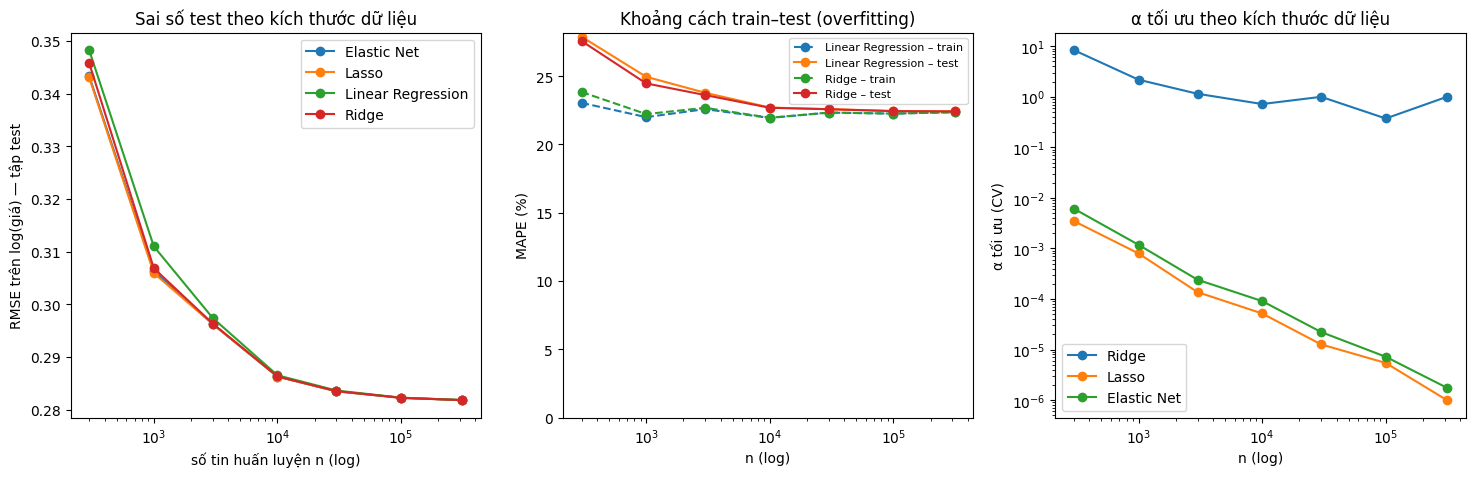

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
piv = lambda col: size_raw.pivot(index="n", columns="mô hình", values=col)
ax = axes[0]
for k, m in enumerate(["Elastic Net", "Lasso", "Linear Regression", "Ridge"]):
    ax.plot(piv("RMSE log").index, piv("RMSE log")[m], "o-", color=f"C{k}", label=m)
ax.set_xscale("log"); ax.legend()
ax.set(xlabel="số tin huấn luyện n (log)", ylabel="RMSE trên log(giá) — tập test", title="Sai số test theo kích thước dữ liệu")
ax = axes[1]
for m, ctr, cte in [("Linear Regression", "C0", "C1"), ("Ridge", "C2", "C3")]:
    ax.plot(piv("MAPE train (%)").index, piv("MAPE train (%)")[m], "o--", color=ctr, label=f"{m} – train")
    ax.plot(piv("MAPE (%)").index, piv("MAPE (%)")[m], "o-", color=cte, label=f"{m} – test")
ax.set_xscale("log"); ax.set_ylim(bottom=0); ax.legend(fontsize=8)
ax.set(xlabel="n (log)", ylabel="MAPE (%)", title="Khoảng cách train–test (overfitting)")
ax = axes[2]
for k, m in enumerate(["Ridge", "Lasso", "Elastic Net"]):
    ax.loglog(piv("alpha").index, piv("alpha")[m].clip(lower=1e-7), "o-", color=f"C{k}", label=m)
ax.legend(); ax.set(xlabel="n (log)", ylabel="α tối ưu (CV)", title="α tối ưu theo kích thước dữ liệu")
save_fig(fig, "09_thi_nghiem_kich_thuoc_du_lieu")

## 9. Lưu mô hình và siêu dữ liệu cho demo

Lưu 6 mô hình vào `models/` và `models/demo_meta.json` (danh sách quận/phường, thống kê để cảnh báo giá trị ngoài vùng dữ liệu, chỉ số trên tập test…) — notebook demo `03` đọc các tệp này. Mô hình **Gradient Boosting** và khoá `hgb_params` do notebook 04 thêm vào sau.

- `wards_by_district`: các phường có ≥ 30 tin trong tập train (đúng ngưỡng `min_frequency` — phường hiếm bị gộp nên mô hình không phân biệt được).
- `ward_display`, `district_display`: tên hiển thị = cách viết phổ biến nhất trong cột gốc `ward`, `district`.

In [19]:
FILES = {"Linear Regression": "linear_regression.joblib", "Ridge": "ridge.joblib", "Lasso": "lasso.joblib",
         "Lasso (1-SE)": "lasso_1se.joblib", "Elastic Net": "elastic_net.joblib", "Random Forest": "random_forest.joblib"}
for name, f in FILES.items():
    joblib.dump(MODELS[name], os.path.join(MODEL_DIR, f), compress=3)
    print(f"{f:26s} {os.path.getsize(os.path.join(MODEL_DIR, f)) / 1e6:7.2f} MB")

# --- siêu dữ liệu cho demo ---
known = train[train["ward_new"] != "unknown"]
wc = known.groupby(["district_key", "ward_new"]).size()
wards_by_district = {d: sorted(g["ward_new"].tolist()) for d, g in wc[wc >= MIN_FREQ].reset_index().groupby("district_key")}
mode_of = lambda s: s.dropna().value_counts().index[0] if s.notna().any() else None   # nhóm không có tên gốc (ward_new = unknown) trả về None, không dùng tới
ward_raw = train.groupby("ward_new")["ward"].agg(mode_of)
wards_used = sorted({w for v in wards_by_district.values() for w in v})
district_raw = train.groupby("district_key")["district"].agg(mode_of)
stats = {}
for key in ["area", "floor_count", "bedroom_count", "bathroom_count", "frontage_width", "road_width"]:
    s = train[key]; stats[key] = {"median": float(s.median()), "p1": float(s.quantile(0.01)), "p99": float(s.quantile(0.99))}

test_metrics = [{k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in r.items()}
                for r in results.reset_index().round(4).to_dict("records")]
best_linear = results.loc[["Linear Regression", "Ridge", "Lasso", "Elastic Net"], "MAPE (%)"].idxmin()

meta = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),
    "features": {"num": NUM, "bin": BIN, "cat": CAT},
    "input_columns_note": "Demo tạo DataFrame với các cột: area, floor_count, bedroom_count, bathroom_count, frontage_width, "
                          "road_width (NaN nếu không biết), các cờ nhị phân 0/1, district_key, ward_loc = district_key + ' | ' + ward_new, "
                          "house_direction, road_type; log_area = log(area)",
    "districts": sorted(train["district_key"].unique().tolist()),
    "district_display": {k: district_raw[k] for k in sorted(district_raw.index)},
    "wards_by_district": wards_by_district,
    "ward_display": {w: ward_raw[w] for w in wards_used},
    "house_directions": sorted(train["house_direction"].unique().tolist()),
    "road_types": sorted(train["road_type"].unique().tolist()),
    "numeric_stats": stats,
    "binary_flags": {"has_so_do": "Có sổ đỏ/sổ hồng", "car_access": "Ô tô vào/đỗ cửa", "is_mat_pho": "Mặt phố/mặt đường",
                     "kinh_doanh": "Kinh doanh được", "lo_goc": "Lô góc/2 mặt thoáng", "no_hau": "Nở hậu", "thang_may": "Có thang máy"},
    "model_files": FILES,
    "best_linear": best_linear,
    "test_metrics": test_metrics,
    "test_size": int(len(test)),
    "train_size": int(len(train)),
}
json.dump(meta, open(os.path.join(MODEL_DIR, "demo_meta.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
print("Đã lưu demo_meta.json | mô hình tuyến tính tốt nhất (MAPE test):", best_linear)

linear_regression.joblib      0.01 MB
ridge.joblib                  0.01 MB
lasso.joblib                  0.01 MB
lasso_1se.joblib              0.01 MB
elastic_net.joblib            0.02 MB


random_forest.joblib         50.90 MB


Đã lưu demo_meta.json | mô hình tuyến tính tốt nhất (MAPE test): Lasso


## Tổng kết

- α, ρ và số hệ số ≠ 0 của từng mô hình: bảng ở mục 3 (`results/ket_qua_so_sanh_mo_hinh.csv`).
- Các tệp đã lưu: 6 mô hình trong `models/`, `models/demo_meta.json`, 8 bảng trong `results/`, 9 hình trong `figures/02/`.
- Bước tiếp theo: chạy `04_danh_gia_bo_sung_va_cai_tien.ipynb` (đọc α từ các mô hình vừa lưu), sau đó `03_demo_dinh_gia_nha.ipynb`.